Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 32)                  │          25,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 784)                 │          25,872 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,064 (203.38 KB)

 Trainable params: 52,064 (203.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0261 - mae: 0.1234 - val_loss: 0.0202 - val_mae: 0.1064
Epoch 2/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0184 - mae: 0.1009 - val_loss: 0.0165 - val_mae: 0.0940
Epoch 3/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0154 - mae: 0.0901 - val_loss: 0.0149 - val_mae: 0.0878
Epoch 4/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0144 - mae: 0.0859 - val_loss: 0.0142 - val_mae: 0.0849
Epoch 5/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0136 - mae: 0.0831 - val_loss: 0.0136 - val_mae: 0.0844
Epoch 6/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0128 - mae: 0.0797 - val_loss: 0.0127 - val_mae: 0.0791
Epoch 7/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0125 - mae: 0.0785 - val_loss: 0.0126 - val_mae: 0.0787
Epoch 8/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0124 - mae: 0.0782 - val_loss: 0.0126 - val_mae: 0.0791
Epoch 9/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - lo

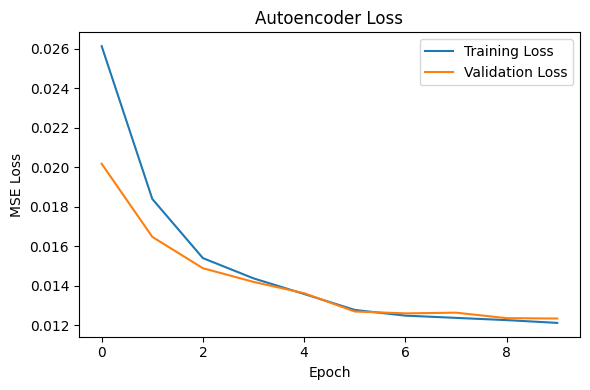

In [3]:
# 3F - Sign Language MNIST: Detect letter Y (label 24) as anomaly using Autoencoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report
from tensorflow import keras


# 1. LOAD + SCALE DATA
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Convert to float32 to reduce memory usage
x_train = train.drop("label", axis=1).values.astype("float32") / 255.0
x = test.drop("label", axis=1).values.astype("float32") / 255.0

# Y (label 24) is considered an anomaly
# 1 = Y (anomaly), 0 = other letters
y = (test["label"].values == 24).astype(int)


# 2. USE ONLY NORMAL DATA FOR TRAINING
# All letters except Y
x_normal = x_train[train["label"].values != 24]


# 3. SPLIT NORMAL DATA INTO TRAINING AND VALIDATION DATA
split = int(len(x_normal) * 0.8)

x_train_normal = x_normal[:split]
x_val_normal = x_normal[split:]


# 4. CREATE DENSE AUTOENCODER
n = x.shape[1]

model = keras.Sequential([
    # Encoder
    keras.layers.Input(shape=(n,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),

    # Decoder
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(n, activation="sigmoid")
])


# 5. COMPILE MODEL
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


# 6. TRAIN AUTOENCODER
# Input = Output because the autoencoder learns reconstruction
history = model.fit(
    x_train_normal,
    x_train_normal,
    validation_data=(x_val_normal, x_val_normal),
    epochs=10,
    batch_size=64,
    verbose=1
)


# 7. RECONSTRUCT TEST DATA
reconstructed = model.predict(x, batch_size=64, verbose=0)


# 8. CALCULATE RECONSTRUCTION ERROR
error = np.mean(
    np.square(x - reconstructed),
    axis=1
)


# 9. SET ANOMALY THRESHOLD
# 95th percentile of normal samples
threshold = np.percentile(error[y == 0], 95)

print("\nThreshold:", threshold)


# 10. PREDICT ANOMALIES
# High reconstruction error = anomaly (letter Y)
y_pred = (error > threshold).astype(int)


# 11. DISPLAY RESULTS
print("\nClassification Report:")
print(classification_report(y, y_pred))


# 12. PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.tight_layout()
plt.show()